   Source Port  Destination Port  NAT Source Port  NAT Destination Port  \
0        57222                53            54587                    53   
1        56258              3389            56258                  3389   
2         6881             50321            43265                 50321   
3        50553              3389            50553                  3389   
4        50002               443            45848                   443   

  Action  Bytes  Bytes Sent  Bytes Received  Packets  Elapsed Time (sec)  \
0  allow    177          94              83        2                  30   
1  allow   4768        1600            3168       19                  17   
2  allow    238         118             120        2                1199   
3  allow   3327        1438            1889       15                  17   
4  allow  25358        6778           18580       31                  16   

   pkts_sent  pkts_received  
0          1              1  
1         10              9  
2 

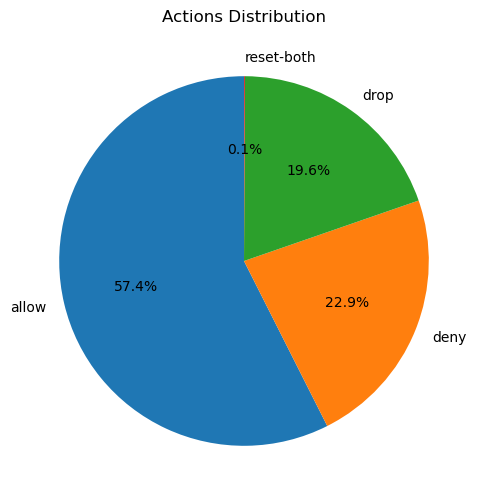

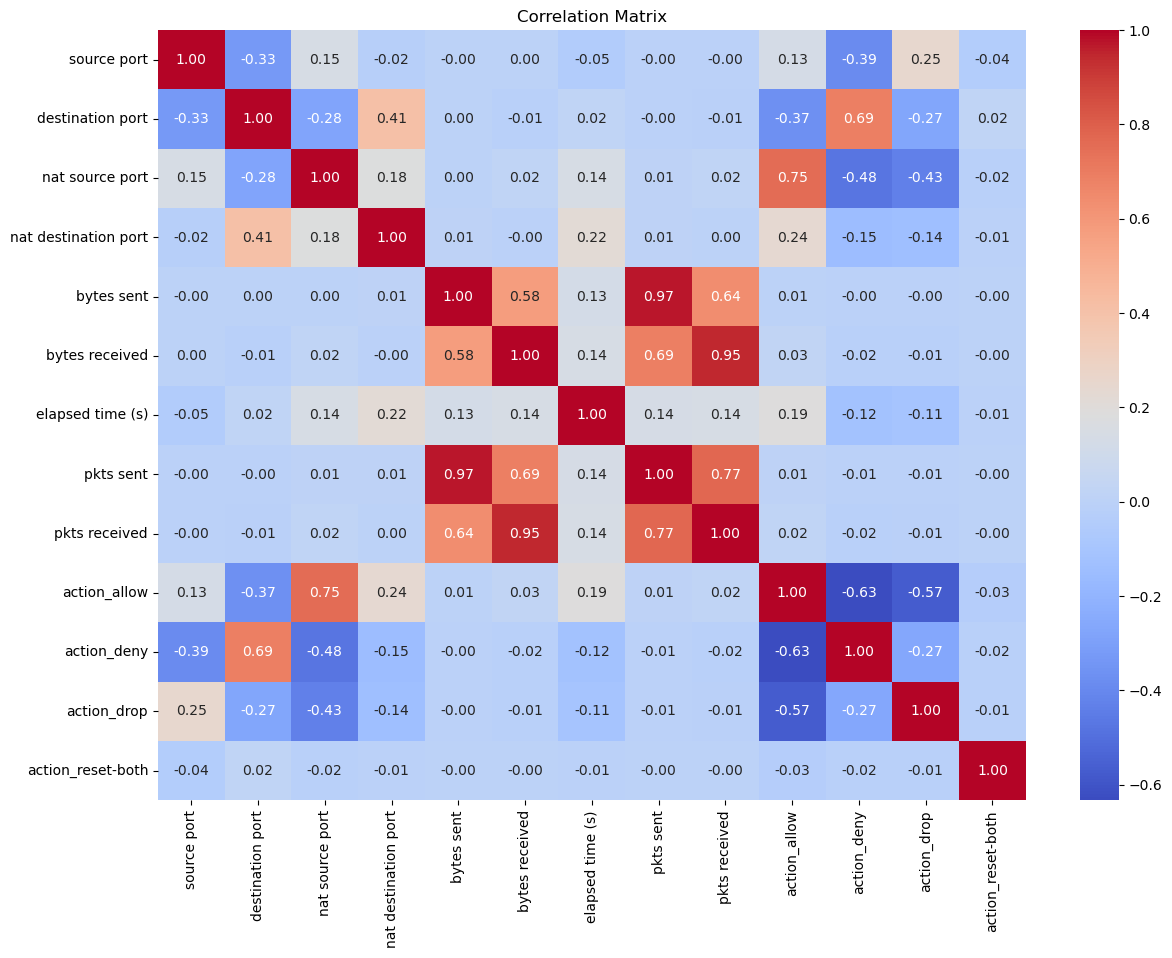

For 1 clusters, inertia: 55591.83043009862
For 2 clusters, inertia: 26504.473714387135
For 3 clusters, inertia: 10333.45509681676
For 4 clusters, inertia: 7940.603399646044
For 5 clusters, inertia: 5768.832759718651
For 6 clusters, inertia: 4471.382020073512
For 7 clusters, inertia: 3832.8849232226794
For 8 clusters, inertia: 3262.914758527758
For 9 clusters, inertia: 2891.751803268634
For 10 clusters, inertia: 2573.638518664865


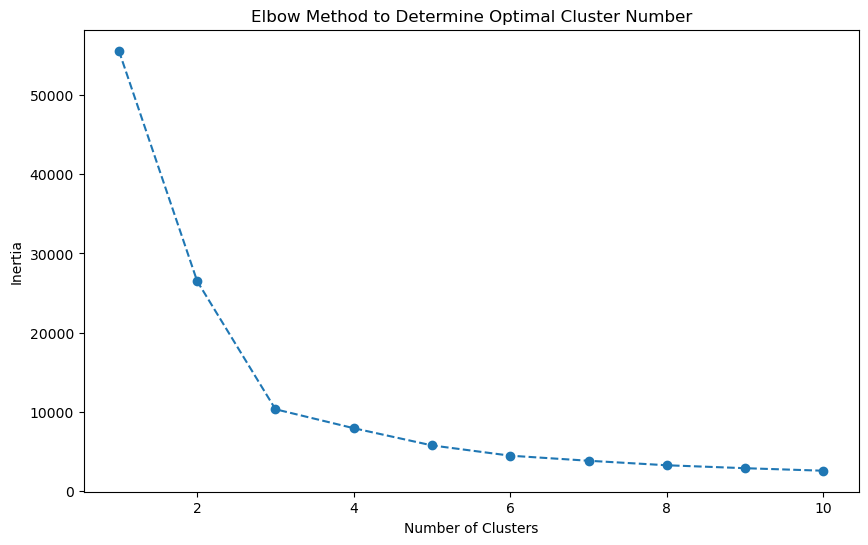

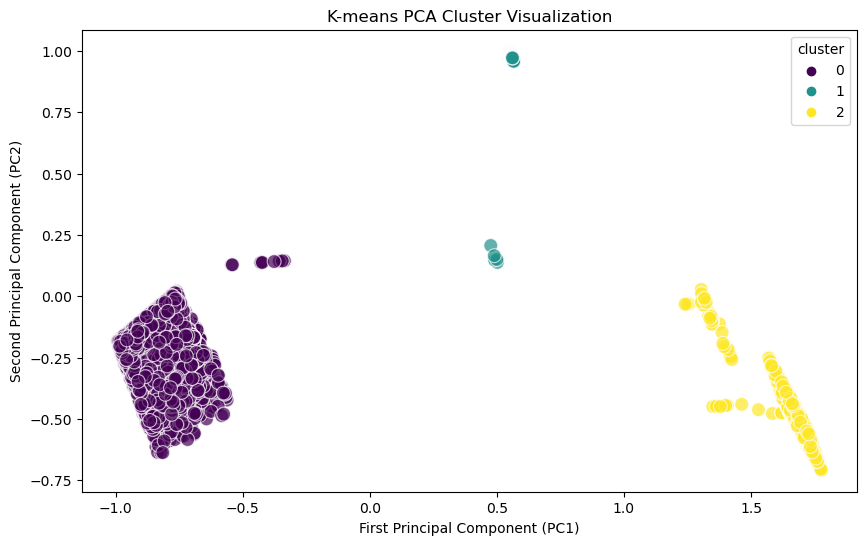

         source port  destination port  nat source port  nat destination port  \
cluster                                                                         
0           0.780120          0.072145         0.511948              0.070926   
1           0.870262          0.006826         0.000000              0.000000   
2           0.587717          0.517267         0.000518              0.000043   

           bytes sent  bytes received  elapsed time (s)     pkts sent  \
cluster                                                                 
0        4.095846e-05    4.054124e-04      1.058666e-02  9.406924e-05   
1        9.171434e-09    0.000000e+00      0.000000e+00  0.000000e+00   
2        2.440544e-08    5.893954e-10      3.074043e-08  3.471923e-09   

         pkts received  action_allow  action_deny  action_drop  \
cluster                                                          
0         3.269735e-04      0.999761     0.000000     0.000000   
1         0.000000e+00      0.

In [ ]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

df = pd.read_csv("log2.csv")

print(df.head())
print(df.info())
print(df.describe())

# Check for missing values
missing_values = df.isnull().sum()
print("Missing values for each feature:\n", missing_values)

# To check if there are any missing values at all
if missing_values.sum() > 0:
    print("There are missing values in the dataset.")
else:
    print("No missing values in the dataset.")

# Renaming the columns
df.columns = ['source port', 'destination port', 'nat source port', 'nat destination port', 'action',
              'bytes', 'bytes sent', 'bytes received', 'packets', 'elapsed time (s)', 'pkts sent', 'pkts received']

# Check inconsistencies
def check_inconsistencies(column_to_check, col1, col2, df):
    inconsistent_rows = df[df[column_to_check] != (df[col1] + df[col2])]

    if not inconsistent_rows.empty:
        print(
            f"Rows where '{column_to_check}' is not the sum of '{col1}' and '{col2}':")
        print(inconsistent_rows)
    else:
        print(
            f"'{column_to_check}' is always the sum of '{col1}' and '{col2}' in every row.")


check_inconsistencies('bytes', 'bytes sent', 'bytes received', df)
check_inconsistencies('packets', 'pkts sent', 'pkts received', df)

# Pie Chart for 'Action'
plt.figure(figsize=(6, 6))
action_counts = df['action'].value_counts()
plt.pie(action_counts, labels=action_counts.index,
        autopct='%1.1f%%', startangle=90)
plt.title('Actions Distribution')
plt.show()


# Drop the columns bytes and packets since they dont provide any additional value, they're always the sums of bytes+bytes sent and pkts sent+pkts received
df.drop(columns=['bytes', 'packets'],
        inplace=True)

# Normalization for continuous values
cols_to_normalize = ['source port', 'destination port', 'nat source port', 'nat destination port',
                     'bytes sent', 'bytes received', 'elapsed time (s)', 'pkts sent', 'pkts received']

scaler = MinMaxScaler()

# Fit and transform the data
df[cols_to_normalize] = scaler.fit_transform(df[cols_to_normalize])

# One-hot encoding for 'Action'
df = pd.get_dummies(df, columns=['action'], prefix=['action'])

# Heatmap for Correlation Matrix
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

################################################################################################################################################################
############################################################# K-MEANS ##########################################################################################
################################################################################################################################################################

# To determine the best number of clusters, we can use the Elbow method
inertia_list = []
for i in range(1, 11):  # I'll try for 1 to 10 clusters
    kmeans = KMeans(n_clusters=i, n_init=10, random_state=42)
    kmeans.fit(df)
    inertia_list.append(kmeans.inertia_)
    print(f"For {i} clusters, inertia: {kmeans.inertia_}")


plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia_list, marker='o', linestyle='--')
plt.title('Elbow Method to Determine Optimal Cluster Number')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

# Train the KMeans model with 3 clusters
optimal_clusters = 3
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)
df['cluster'] = kmeans.fit_predict(df)

# Visualizing the clusters
# Using PCA for 2D visualization due to multiple features. This provides an approximation of our multi-dimensional data in two dimensions.
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(df)
principalDf = pd.DataFrame(data=principalComponents, columns=['PC1', 'PC2'])
principalDf['cluster'] = df['cluster']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=principalDf, x='PC1', y='PC2',
                hue='cluster', palette='viridis', s=100, alpha=0.7)
plt.title('K-means PCA Cluster Visualization')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.show()


# Interpreting the results
cluster_summary = df.groupby('cluster').mean()
print(cluster_summary)

kmeans_3 = KMeans(n_clusters=3, random_state=42)
kmeans_3.fit(df)
print(f"Inertia for 3 clusters: {kmeans_3.inertia_}")


# Define a function to predict the cluster for new data
def predict_cluster(new_data, kmeans_model, scaler):

    # Check if 'action' exists in new_data and if it does, one-hot encode it
    if 'action' in new_data.columns:
        new_data = pd.get_dummies(
            new_data, columns=['action'], prefix=['action'])

    # Make sure new_data has all the columns in the original df (excluding 'cluster')
    for col in df.columns:
        if col not in new_data.columns and col != 'cluster':
            new_data[col] = 0

    # Order columns to match original df
    new_data = new_data[df.columns.drop('cluster')]

    # Scale the new data
    new_data[cols_to_normalize] = scaler.transform(new_data[cols_to_normalize])

    # Predict cluster label
    cluster_label = kmeans_model.predict(new_data)

    return cluster_label

# Test the function with a sample data point
sample_data = pd.DataFrame({
    'source port': [57222],
    'destination port': [53],
    'nat source port': [54587],
    'nat destination port': [53],
    'action': ['allow'],
    'bytes sent': [94],
    'bytes received': [83],
    'elapsed time (s)': [30],
    'pkts sent': [1],
    'pkts received': [1]
})

predicted_cluster = predict_cluster(sample_data, kmeans, scaler)
print(f"Predicted cluster for the sample data: {predicted_cluster[0]}")


# After you've computed your clusters using KMeans
silhouette_avg = silhouette_score(df, df['cluster'])

print(f"Silhouette Score for {optimal_clusters} clusters: {silhouette_avg}")

# Compute Davies-Bouldin Index for KMeans
db_score_kmeans = davies_bouldin_score(
    df.drop(['cluster'], axis=1), df['cluster'])
print(f'Davies-Bouldin Index for KMeans: {db_score_kmeans}')

################################################################################################################################################################
############################################################# DBSCAN ##########################################################################################
################################################################################################################################################################

dbscan = DBSCAN(eps=0.5, min_samples=5)
df['dbscan_cluster'] = dbscan.fit_predict(df)


principalDf['dbscan_cluster'] = df['dbscan_cluster']

distinct_colors = ['#1f77b4', '#ff7f0e', '#2ca02c',
                   '#d62728', '#9467bd', '#8c564b', '#e377c2']


plt.figure(figsize=(10, 6))
sns.scatterplot(data=principalDf, x='PC1', y='PC2',
                hue='dbscan_cluster', palette=distinct_colors, s=100, alpha=0.7)
plt.title('DBSCAN PCA Cluster Visualization')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.show()


dbscan_cluster_summary = df.groupby('dbscan_cluster').mean()
print(dbscan_cluster_summary)


def predict_dbscan_cluster(new_data, dbscan_model, scaler):
    # Check if 'action' exists in new_data and if it does, one-hot encode it
    if 'action' in new_data.columns:
        new_data = pd.get_dummies(
            new_data, columns=['action'], prefix=['action'])

    # Make sure new_data has all the columns in the original df (excluding 'dbscan_cluster')
    for col in df.columns:
        if col not in new_data.columns and col != 'dbscan_cluster':
            new_data[col] = 0

    # Order columns to match original df
    new_data = new_data[df.columns.drop('dbscan_cluster')]

    # Scale the new data
    new_data[cols_to_normalize] = scaler.transform(new_data[cols_to_normalize])

    # Predict cluster label (-1 for noise) using DBSCAN
    cluster_label = dbscan_model.fit_predict(new_data)
    return cluster_label


# Predict DBSCAN cluster label for the sample data
predicted_dbscan_cluster = predict_dbscan_cluster(sample_data, dbscan, scaler)

# Print the predicted cluster label
print(
    f"Predicted DBSCAN cluster for the sample data: {predicted_dbscan_cluster[0]}")

# Exclude noise points (cluster label -1) from evaluation as many metrics are undefined for single-sample clusters
filtered_data = df[df['dbscan_cluster'] != -1]

# Compute Silhouette Score
sil_score = silhouette_score(filtered_data.drop(
    'dbscan_cluster', axis=1), filtered_data['dbscan_cluster'])
print(f'Silhouette Score: {sil_score}')

# Compute Davies-Bouldin Index
db_score = davies_bouldin_score(filtered_data.drop(
    'dbscan_cluster', axis=1), filtered_data['dbscan_cluster'])
print(f'Davies-Bouldin Index: {db_score}')


In [ ]:
print("Jupyter Notebook was not able to process the rest of the code, providing the rest of the outputs below:")

In [1]:
print(""" source port  destination port  nat source port  nat destination port  ...  action_deny  action_drop  action_reset-both  cluster
dbscan_cluster                                                                        ...

-1                 0.787952          0.066959         0.664482              0.066959  ...          0.0          0.0           0.333333      
0.0
 0                 0.780183          0.072150         0.511937              0.070930  ...          0.0          0.0           0.000000      
0.0
 1                 0.870361          0.006790         0.000000              0.000000  ...          0.0          1.0           0.000000      
1.0
 2                 0.588355          0.517343         0.000486              0.000033  ...          1.0          0.0           0.000000      
2.0
 3                 0.348402          0.488705         0.012480              0.003878  ...          0.0          0.0           1.000000      
2.0
 4                 0.616663          0.097826         0.000000              0.000000  ...          0.0          0.0           1.000000      
1.0
 5                 0.436543          0.051713         0.436537              0.051713  ...          0.0          0.0           1.000000      
0.0

[7 rows x 14 columns]
Predicted DBSCAN cluster for the sample data: -1
Silhouette Score: 0.7096765918892421
Davies-Bouldin Index: 0.4094160220828009""")

 source port  destination port  nat source port  nat destination port  ...  action_deny  action_drop  action_reset-both  cluster
dbscan_cluster                                                                        ...

-1                 0.787952          0.066959         0.664482              0.066959  ...          0.0          0.0           0.333333      
0.0
 0                 0.780183          0.072150         0.511937              0.070930  ...          0.0          0.0           0.000000      
0.0
 1                 0.870361          0.006790         0.000000              0.000000  ...          0.0          1.0           0.000000      
1.0
 2                 0.588355          0.517343         0.000486              0.000033  ...          1.0          0.0           0.000000      
2.0
 3                 0.348402          0.488705         0.012480              0.003878  ...          0.0          0.0           1.000000      
2.0
 4                 0.616663          0.097826         0